# Introdução às Redes Neurais e Deep Learning

## Redes Neurais Convolucionais

São basicamente redes neurais que utilizam camadas convolucionais baseadas na operação matemática da convolução. As camadas convolucionais consistem em um conjunto de filtros (*kernels*) que podem ser consideradas como matrizes bidimensionais de números.

Podemos usar uma imagem de entrada e um filtro   para produzir uma imagem de saída convoluindo o filtro com a imagem de entrada. A operação de convolução entre duas funções $f(t)$ e $g(t)$ é a integral 
$$f(t)*g(t)= \int_{-\infty}^{\infty} f(t-\tau)g(\tau)d\tau$$

Isso consiste em:

* Sobrepor o filtro sobre a imagem em algum local.
* Realizar a multiplicação elemento a elemento entre os valores no filtro e seus valores correspondentes na imagem.
* Somar todos os produtos elemento a elemento. Essa soma é o valor de saída para o pixel de destino na imagem de saída.
Repetir para todos os locais.

Considere uma imagem consistindo de 16 *pixels* em uma estrutura matricial 4x4, onde cada número da matriz corresponde à intensidade do *pixel*, a ser convoluída  com um filtro representado por uma matriz de dimenõses 3 X 3. Durante o processo o filtro irá se sobrepor aos elementos na sub-matriz 3x3 no canto superior esquerdo, gerando o primeiro *pixel* na imagem convoluída. Depois o filtro desloca-se um nível para direita, e um novo *pixel* é gerado. O processo é repetido depois do filtro ser deslocado 1 nível avaixo sobre a imagem original, resultanto em mais dois *pixels*. Este processo resultando em uma matriz 2 X 2é mostrado na figura abaixo:

<div>
<img src="Files\\NiceMatrix_Conv_2D.png" width="1000" height="1000">   
</div>


*Stride*  é a distância que o filtro percorre em cada passo ao longo de uma direção. No exemplo acima usamos *stride*=1. 

O filtro mostrado no exemplo acima é conhecido como filtro de Sobel, usado para calcular o gradiente de intensidade luminosa na direção horizontal  (e portanto, identificar linhas horizontais em uma imagem)  e é apropriado para identificar linhas verticais em uma imagem. A transposição de um filtro de Sobel resulta em um filtro de Sobel horizontal. Abaixo, segundo um exemplo  extraído de 
https://towardsdatascience.com/sobel-operator-in-image-processing-1d7cdda8cadb/
podemos ilustrar a operação dos filtros de Sobel vertical e horizontal à uma imagem em tons de cinza com apena 5x5 pixels:


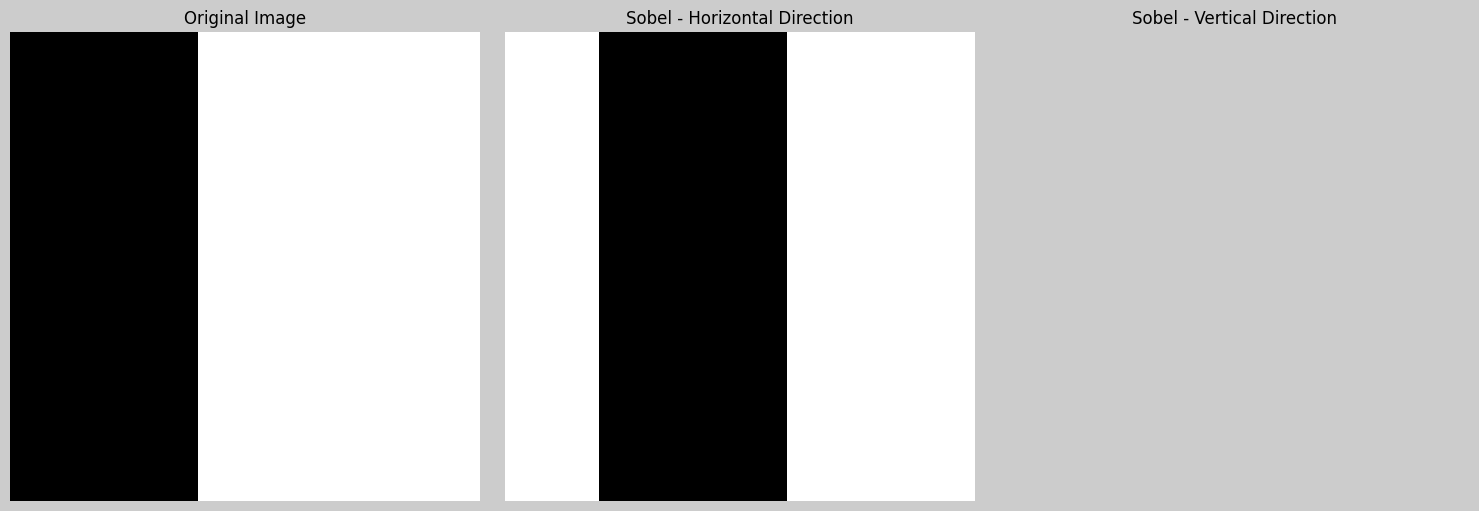

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import warnings

warnings.filterwarnings('ignore')  # Suppress all warnings

# Imagem de entrada
image = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0],
    [200, 200, 200, 200, 200],
    [200, 200, 200, 200, 200],
    [200, 200, 200, 200, 200]
])
image=image.T

# Filtro de Sobel vertical
G_x = np.array([
    [-1, 0, +1],
    [-2, 0, +2],
    [-1, 0, +1]
])

## Filtro de Sobel horizontal
G_y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [+1, +2, +1]
])

# Apply the Sobel kernels to the image
output_x = ndimage.convolve(image.astype(float), G_x)
output_y = ndimage.convolve(image.astype(float), G_y)

# Define the light grey color for the background
light_grey = [0.8, 0.8, 0.8]  # RGB values for light grey

# Normalize the Sobel outputs
norm_output_x = (output_x - output_x.min()) / (output_x.max() - output_x.min())
norm_output_y = (output_y - output_y.min()) / (output_y.max() - output_y.min())

# Set the background color of the plots
plt.rcParams['figure.facecolor'] = light_grey
plt.rcParams['axes.facecolor'] = light_grey

# Plot the images with the light grey background
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(norm_output_x, cmap='gray')
axes[1].set_title('Sobel - Horizontal Direction')
axes[1].axis('off')

axes[2].imshow(norm_output_y, cmap='gray')
axes[2].set_title('Sobel - Vertical Direction')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## *Padding*

Como vimos, convoluindo uma imagem 4x4 com um filtro 3x3 resulta em uma imagem de saída de dimensão 2x2. Entretanto, usando *padding* a imagem de saída pode ter a mesma dimensão que a imagem original. Para isto, zeros são adicionados em torno da imagem de forma que o filtro pode ser sobreposto nela em mais lugares. Esta técnica é chamada de "**same Padding**". Caso *padding* não seja usado, algumas vezes será chamado de "**Valid Padding**". Veja na figura abaixo que com a técnica *same-Padding* e *stride*=1 teremos 4 convoluções por linha, e 4 por coluna, resultando em uma matriz 4 X 4. 

$$Conv=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix} * \begin{bmatrix} 0&0&0&0&0&0\\0&0&50&0&29&0\\0&0&80&31&2&0\\0&33&90&0&75&0\\0&0&9&0&95&0\\0&0&0&0&0&0&\end{bmatrix}=\begin{bmatrix} 180&31&-120&-31\\300&29&-192&-62\\269&-35&-22&-31\\108&-33&157&0\end{bmatrix}$$

## Camadas Convolutivas

As redes convolucionais  incluem camadas de convolução que usam um conjunto de filtros para transformar imagens de entrada em imagens de saída. O parâmetro principal de uma camada de convolução é o número de filtros que ela possui.

Se uma rede usa uma pequena camada de convolução com 8 filtros na camada inicial,  então se, por exemplo, a imagem de entrada tiver resolução de 28x28 *pixels*, eles serão transformados em um volume de saída de 26x26x8 (se *valid padding* está sendo usado). 

Cada um dos 8 filtros na camada de convolução produz uma saída de 26x26, os quais empilhados formam um volume de 26x26x8. Considerando que os 8 filtros tem dimensão3×3, então o número de pesos será igual à 8 X 9 = 72 ! Isto é muito menos do que se fosse uma camada completamente conectada. 

In [4]:
# ==============================
# Exemplo de Função de convolução
# ==============================

def convolve2d(image, kernel, padding=0, stride=1):
    # Na convolução o filtro pode ser invertido antes de atravessar a imagem, como acontece na integral de convolução. 
    #kernel = np.flipud(np.fliplr(kernel))  # Rotação 180°
    x_k, y_k = kernel.shape
    x_i, y_i = image.shape

    if padding > 0:
        image_padded = np.pad(image, pad_width=padding, mode='constant')
    else:
        image_padded = image
    #determina a dimensão da imagem de saída com base nos valores de padding e stride
    x_o = ((x_i + 2 * padding - x_k) // stride) + 1
    y_o = ((y_i + 2 * padding - y_k) // stride) + 1
    output = np.zeros((x_o, y_o))

    for i in range(0, x_o):
        for j in range(0, y_o):
            region = image_padded[i*stride:i*stride+x_k, j*stride:j*stride+y_k]
            output[i, j] = np.sum(region * kernel)

    return output

In [5]:
import numpy as np

# Imagem de entrada (4x4)
image = np.array([
    [0, 50, 0, 29],
    [0,80, 31, 2],
    [33, 90, 0, 75],
    [0, 9, 0, 95]
])

# Filtro (3x3)
kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

# Passo 1: Convolução
conv_out = convolve2d(image, kernel, padding=1)
print("\nSaída da Convolução:")
print(conv_out)


Saída da Convolução:
[[ 180.   31. -120.  -31.]
 [ 300.   29. -192.  -62.]
 [ 269.  -35.  -22.  -31.]
 [ 108.  -33.  157.    0.]]


## *Pooling*

Pixels vizinhos em imagens tendem a ter valores semelhantes, portanto, as camadas de convolução normalmente também produzem valores semelhantes para pixels vizinhos nas saídas. Como resultado, grande parte da informação contida na saída de uma camada de convolução é redundante. Por exemplo, se usarmos um filtro de detecção de bordas e encontrarmos uma borda forte em um determinado local, é provável que também encontremos bordas relativamente fortes em locais deslocados de um pixel em relação ao original. No entanto, todas essas bordas se referem a mesma , nâo constituem informação adicional.

Uma camada de *pooling* é um tipo de camada de rede que reduz a resolução e agrega informações dispersas. Sua função principal é remover informações redundantes, reduzindo assim a quantidade de computação e memória necessárias, o que torna o modelo mais robusto à pequenas variações na entrada. Assim as camadas de *pooling* reduzem o tamanho da entrada fornecida agrupando os seus valores. Este agrupamento geralmente é feito por uma operação simples como máximo, mínimo ou média. Quando usamos o máximo, o nome utilizado para esta técnica é *max Pooling*.

Como funciona o *Max Pooling*:

1) Varredura: O *Max Pooling* move uma pequena janela (geralmente 2x2 ou 3x3) sobre o mapa de características de entrada.

2) Seleção: Em cada janela, o *Max Pooling* seleciona o valor máximo. É como escolher a informação mais importante naquela área.

3) Redução de resolução: Após selecionar os valores máximos de todas essas janelas, o *Max Pooling* reduz o tamanho do mapa de características. A imagem fica menor, mas os detalhes essenciais permanecem intactos.

Assim, para realizar o *max pooling*, percorre-se a imagem de entrada em blocos 2x2 (se o tamanho do bloco = 2) e coloca-se o valor máximo na imagem de saída no pixel correspondente.
O *pooling* divide a largura e a altura da entrada pelo tamanho do bloco. Para a rede 28x28, colocaremos uma camada de *max pooling* com um tamanho de bloco  2 logo após a camada de convolução inicial. A camada de *pooling* transformará uma entrada de 26x26x8 em uma saída de 13x13x8:

In [6]:
# =======================================
# Max Pooling
# =======================================
def max_pooling(feature_map, size=2, stride=1):
    x_f, y_f = feature_map.shape
    x_o = ((x_f - size) // stride) + 1
    y_o = ((y_f - size) // stride) + 1
    pooled = np.zeros((x_o, y_o))

    for i in range(x_o):
        for j in range(y_o):
            region = feature_map[i*stride:i*stride+size, j*stride:j*stride+size]
            pooled[i, j] = np.max(region)

    return pooled

In [7]:
pool_out = max_pooling(conv_out, size=2, stride=1)
print("\nSaída do Max Pooling:")
print(pool_out)


Saída do Max Pooling:
[[300.  31. -31.]
 [300.  29. -22.]
 [269. 157. 157.]]


<div>
<img src="Files\\Pipeline de CNN_ Entrada ao Flatten.png" width="1000" height="1000">   
</div>
Fonte: chatGPT